Character-level

In [50]:

from pathlib import Path
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,)

# =========================
# 1. 数据路径
# =========================
DATA_DIR = Path("../data/raw/COLDataset/COLDataset")


# =========================
# 2. 读取数据
# =========================
train_df = pd.read_csv(DATA_DIR / "train.csv", encoding="utf-8-sig",)
dev_df = pd.read_csv(DATA_DIR / "dev.csv", encoding="utf-8-sig",)


# =========================
# 3. 清理文本
# =========================
# 缺失值填成空字符串（TF-IDF 不接受 NaN）   强制转字符串（防止某些行被读成数字或 float）  去掉首尾空白
for df in [train_df, dev_df]:
    df["TEXT"] = df["TEXT"].fillna("").astype(str).str.strip()


X_train = train_df["TEXT"]
y_train = train_df["label"]

X_dev = dev_df["TEXT"]
y_dev = dev_df["label"]

In [51]:
# =========================
# 4. TF-IDF
# =========================
# analyzer="char"：按字符切分，不用分词。这是处理中文最常用的省事做法，避免依赖 jieba 等分词器，也避免分词错误带来的噪声。
# ngram_range=(2, 5)：使用 2~5 个字符的连续组合（bigram 到 5-gram）。中文单字信息量低，字符 n-gram 能捕捉“地域黑”“女拳”这类短语级线索。
# min_df=2：某个字符 n-gram 至少在 2 个文档中出现才保留，过滤掉极罕见的噪声特征，缩小词表。
# sublinear_tf=True：词频用 1 + log(tf) 而不是原始 tf，抑制高频词过度主导，对长文本更稳。
vectorizer = TfidfVectorizer(analyzer="char", ngram_range=(2, 5), min_df=2, sublinear_tf=True,)

X_train_tfidf = vectorizer.fit_transform(X_train)  # 训练集：fit + transform
X_dev_tfidf = vectorizer.transform(X_dev)  # 验证/测试集：只 transform

print("TF-IDF feature shape:")
print("Train:", X_train_tfidf.shape)
print("Dev:  ", X_dev_tfidf.shape)


# =========================
# 5. Logistic Regression
# =========================
model = LogisticRegression(max_iter=2000, random_state=42)
model.fit(X_train_tfidf, y_train,)


# =========================
# 6. Dev evaluation
# =========================
dev_pred = model.predict(X_dev_tfidf)

print("\n" + "=" * 60)
print("DEV RESULT")
print("=" * 60)

print("Accuracy:", accuracy_score(y_dev, dev_pred),)
print("\nClassification Report:")
print(classification_report( y_dev, dev_pred, target_names=["Safe", "Offensive"],))

print("Confusion Matrix:")
print(confusion_matrix( y_dev, dev_pred,))

TF-IDF feature shape:
Train: (25726, 338474)
Dev:   (6431, 338474)

DEV RESULT
Accuracy: 0.8815114290157052

Classification Report:
              precision    recall  f1-score   support

        Safe       0.88      0.89      0.88      3220
   Offensive       0.89      0.88      0.88      3211

    accuracy                           0.88      6431
   macro avg       0.88      0.88      0.88      6431
weighted avg       0.88      0.88      0.88      6431

Confusion Matrix:
[[2855  365]
 [ 397 2814]]


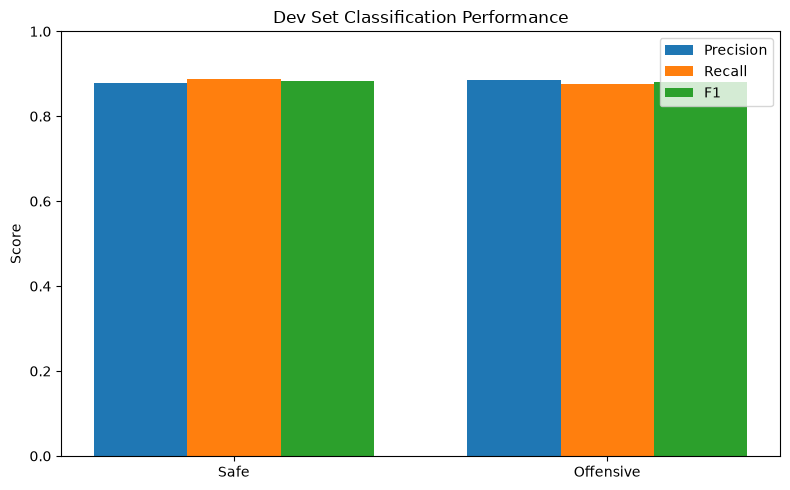

In [52]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, _ = precision_recall_fscore_support(y_dev, dev_pred, labels=[0, 1], zero_division=0,)
labels = ["Safe", "Offensive"]

x = range(len(labels))
width = 0.25

plt.figure(figsize=(8, 5))
plt.bar([i - width for i in x], precision, width=width, label="Precision",)
plt.bar(x, recall,  width=width, label="Recall",)
plt.bar([i + width for i in x], f1, width=width, label="F1",)

plt.xticks(x, labels)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Dev Set Classification Performance")
plt.legend()

plt.tight_layout()
plt.show()

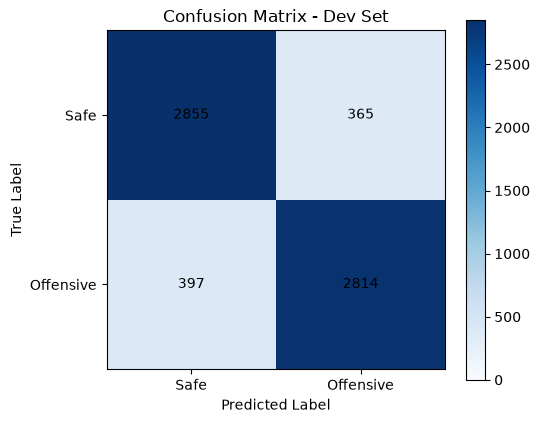

In [53]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_dev, dev_pred,)
labels = ["Safe", "Offensive"]

plt.figure(figsize=(5.5, 4.5))
plt.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max())

plt.xticks(range(len(labels)), labels,)
plt.yticks(range(len(labels)), labels,)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Dev Set")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center",)

plt.colorbar()

plt.tight_layout()
plt.show()

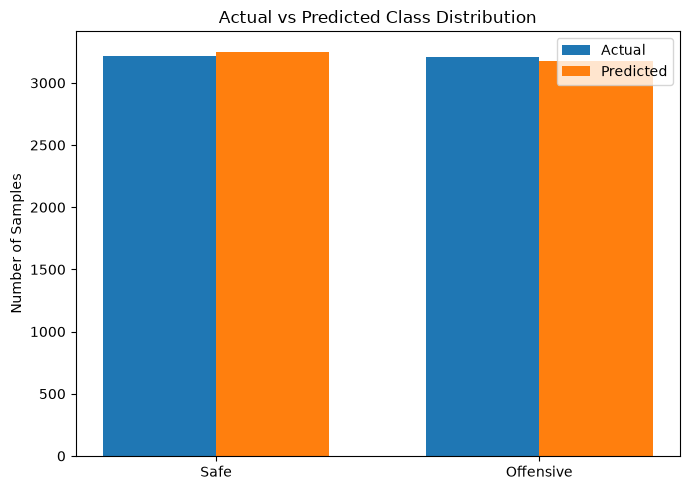

In [54]:
import matplotlib.pyplot as plt
import pandas as pd

actual_counts = pd.Series(y_dev).value_counts().sort_index()
predicted_counts = pd.Series(dev_pred).value_counts().sort_index()

labels = ["Safe", "Offensive"]
x = range(len(labels))
width = 0.35

plt.figure(figsize=(7, 5))
plt.bar([i - width / 2 for i in x],  actual_counts,  width=width, label="Actual",)
plt.bar([i + width / 2 for i in x],  predicted_counts,  width=width, label="Predicted",)

plt.xticks(x, labels)
plt.ylabel("Number of Samples")
plt.title("Actual vs Predicted Class Distribution")
plt.legend()

plt.tight_layout()
plt.show()

Word-level

In [55]:
# python -m pip install jieba
import jieba
import re

def chinese_tokenizer(text):
    words = jieba.lcut(text)

    # 去除纯标点符号
    words = [ word.strip() for word in words  if re.search(r"[\u4e00-\u9fffA-Za-z0-9]", word)]
    return words

In [56]:
# analyzer="word"	按词语处理
# tokenizer	使用 jieba 分词
# token_pattern=None	禁用默认正则分词规则
# ngram_range=(1,2)	使用 unigram 和 bigram
# min_df=2	至少出现在两个文档中
# sublinear_tf=True	使用对数词频
word_vectorizer = TfidfVectorizer(analyzer="word", tokenizer=chinese_tokenizer,  token_pattern=None, 
                                  ngram_range=(1, 2), min_df=2, sublinear_tf=True,)


In [57]:
# Word-level TF-IDF

X_train_word = word_vectorizer.fit_transform(X_train)
X_dev_word = word_vectorizer.transform(X_dev)

print("Word TF-IDF feature shape:")
print("Train:", X_train_word.shape)
print("Dev:", X_dev_word.shape)


# Logistic Regression
word_model = LogisticRegression(max_iter=2000, random_state=42,)
word_model.fit(X_train_word, y_train)


# Validation prediction
word_pred = word_model.predict(X_dev_word)

# Evaluation
print("\nWORD-LEVEL TF-IDF RESULT")
print("Accuracy:", accuracy_score(y_dev, word_pred))
print(classification_report(y_dev, word_pred, target_names=["Safe", "Offensive"],))

print("Confusion Matrix:")
print(confusion_matrix(y_dev, word_pred))

Word TF-IDF feature shape:
Train: (25726, 79288)
Dev: (6431, 79288)

WORD-LEVEL TF-IDF RESULT
Accuracy: 0.8897527600684186
              precision    recall  f1-score   support

        Safe       0.89      0.89      0.89      3220
   Offensive       0.89      0.89      0.89      3211

    accuracy                           0.89      6431
   macro avg       0.89      0.89      0.89      6431
weighted avg       0.89      0.89      0.89      6431

Confusion Matrix:
[[2878  342]
 [ 367 2844]]


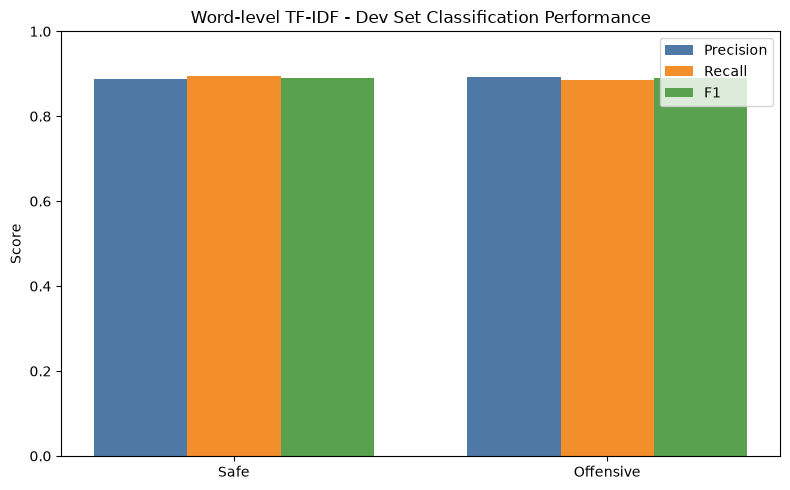

In [58]:

labels = ["Safe", "Offensive"]

# =====================================
# Plot 1: Precision / Recall / F1
# =====================================
precision, recall, f1, _ = precision_recall_fscore_support(
    y_dev, word_pred, labels=[0, 1], zero_division=0
)

x = range(len(labels))
width = 0.25

plt.figure(figsize=(8, 5))
plt.bar([i - width for i in x], precision, width=width, label="Precision", color="#4E79A7")
plt.bar(x, recall, width=width, label="Recall", color="#F28E2B")
plt.bar([i + width for i in x], f1, width=width, label="F1", color="#59A14F")

plt.xticks(x, labels)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Word-level TF-IDF - Dev Set Classification Performance")
plt.legend()

plt.tight_layout()
plt.show()



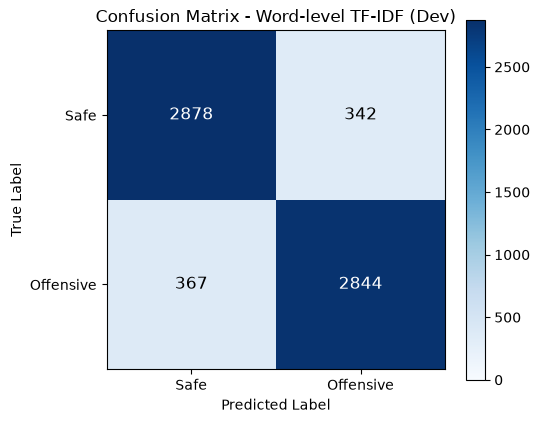

In [59]:
# =====================================
# Plot 2: Confusion Matrix
# =====================================
cm = confusion_matrix(y_dev, word_pred)

plt.figure(figsize=(5.5, 4.5))
plt.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max())

plt.xticks(range(len(labels)), labels)
plt.yticks(range(len(labels)), labels)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Word-level TF-IDF (Dev)")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ratio = cm[i, j] / cm.max() if cm.max() else 0
        plt.text(
            j, i, cm[i, j],
            ha="center", va="center",
            color="white" if ratio > 0.55 else "black", fontsize=12,)

plt.colorbar()
plt.tight_layout()
plt.show()



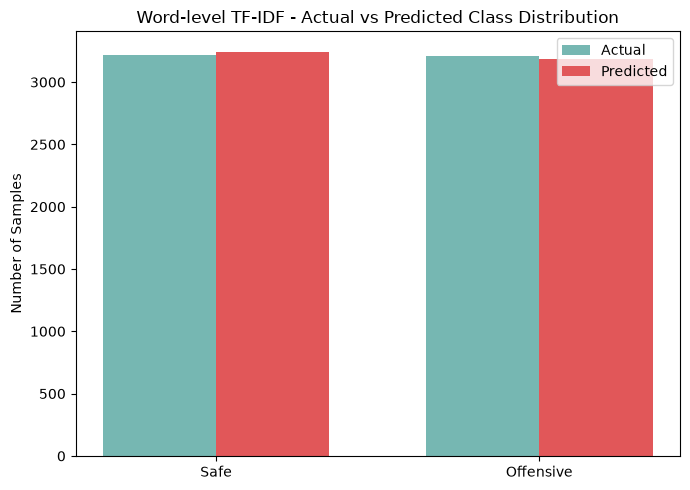

In [60]:
# =====================================
# Plot 3: Actual vs Predicted Distribution
# =====================================
actual_counts = pd.Series(y_dev).value_counts().sort_index()
predicted_counts = pd.Series(word_pred).value_counts().sort_index()

x = range(len(labels))
width = 0.35

plt.figure(figsize=(7, 5))
plt.bar([i - width / 2 for i in x], actual_counts, width=width, label="Actual", color="#76B7B2")
plt.bar([i + width / 2 for i in x], predicted_counts, width=width, label="Predicted", color="#E15759")

plt.xticks(x, labels)
plt.ylabel("Number of Samples")
plt.title("Word-level TF-IDF - Actual vs Predicted Class Distribution")
plt.legend()

plt.tight_layout()
plt.show()